# Milestone 6b - Predictive Model: Which Customers Are Drifting Away? (Churn)
**Business question (Q5):** which loyalty members are likely to stop shopping in the next 90 days, so CRM can target
them with a win-back offer *before* they leave?

**Definition.** At a snapshot date *C*, an *active member* is one who bought at least once in the 180 days before *C*
and joined at least 30 days before *C*. They are labelled **churned = 1 if they make no purchase in the 90 days after C**.
(Retail has no contract to cancel, so churn must be defined from behaviour; 90 days is ~5x the median gap between visits.)

**Leakage control.** Features use only transactions *before* C; labels only transactions in [C, C+90).

**Validation design - out of time.**
* Train on snapshots **2025-10-01, 2026-01-01 and 2026-04-01** (stacked), tune with 5-fold grouped CV (customers never
  appear in both a training and validation fold).
* Test once on the later snapshot **2026-07-01** (labels Jul-Sep 2026) - a genuinely unseen future period that includes
  the Nakuru competitor effect and the 2026 cost-of-living squeeze.

**Models:** a rules baseline (rank by recency), logistic regression, gradient boosting.

In [1]:
import sys; sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from config import PROCESSED, FIGURES, TABLES, set_style, PALETTE, TEXT_2
set_style()

tx = pd.read_pickle(PROCESSED / "transactions.pkl")
sales = pd.read_pickle(PROCESSED / "sales_lines.pkl")
customers = pd.read_csv(PROCESSED / "customers.csv", parse_dates=["signup_date"])
stores = pd.read_csv(PROCESSED / "stores.csv")
m = tx[tx.is_member].copy()
m["date"] = m.transaction_datetime.dt.normalize()
cat_per_tx = sales[sales.is_member & (sales.quantity > 0)].groupby(["transaction_id"]).category.nunique()
m["n_cats"] = m.transaction_id.map(cat_per_tx).fillna(0)
cust_cats = sales[sales.is_member & (sales.quantity > 0)][["customer_id", "date", "category"]]
print(f"{len(m):,} member receipts, {m.customer_id.nunique():,} members")

164,435 member receipts, 5,536 members


## Feature engineering at a snapshot date

In [2]:
HOME = customers.merge(stores[["store_id", "county", "store_format"]], left_on="home_store_id", right_on="store_id")

def build_snapshot(C, label=True, horizon=90):
    C = pd.Timestamp(C)
    h = m[(m.date < C) & (m.date >= C - pd.Timedelta(days=365))]
    act = h[h.date >= C - pd.Timedelta(days=180)].customer_id.unique()
    elig = HOME[(HOME.customer_id.isin(act)) & (HOME.signup_date <= C - pd.Timedelta(days=30))].copy()
    h = h[h.customer_id.isin(elig.customer_id)]
    days_ago = (C - h.date).dt.days
    grp = h.assign(days_ago=days_ago).groupby("customer_id")
    f = pd.DataFrame({
        "recency_days": grp.days_ago.min(),
        "freq_30": grp.days_ago.apply(lambda s: (s < 30).sum()),
        "freq_90": grp.days_ago.apply(lambda s: (s < 90).sum()),
        "freq_180": grp.days_ago.apply(lambda s: (s < 180).sum()),
        "freq_365": grp.size(),
        "spend_90": grp.apply(lambda d: d.net_amount[d.days_ago < 90].sum(), include_groups=False),
        "spend_365": grp.net_amount.sum(),
        "avg_basket": grp.net_amount.mean(),
        "last_basket": h.sort_values("date").groupby("customer_id").net_amount.last(),
        "avg_cats_per_visit": grp.n_cats.mean(),
        "promo_share": grp.has_promo.mean(),
        "mpesa_share": grp.payment_method.apply(lambda s: (s == "M-Pesa").mean()),
        "card_share": grp.payment_method.apply(lambda s: (s == "Card").mean()),
        "weekend_share": grp.date.apply(lambda s: (s.dt.dayofweek >= 5).mean()),
        "n_stores": grp.store_id.nunique(),
    })
    gaps = h.sort_values("date").groupby("customer_id").date.apply(lambda s: s.diff().dt.days.dropna())
    gstats = gaps.groupby(level=0).agg(["mean", "std"]).rename(columns={"mean": "gap_mean", "std": "gap_std"})
    f = f.join(gstats)
    f["gap_mean"] = f.gap_mean.fillna(180); f["gap_std"] = f.gap_std.fillna(0)
    # momentum: visits in the last 45 days vs the 45 before that (drifting customers slow down first)
    f["trend_45"] = grp.days_ago.apply(lambda s: ((s < 45).sum() + 1) / ((s.between(45, 89)).sum() + 1))
    f["recency_vs_gap"] = f.recency_days / f.gap_mean.clip(lower=1)
    cc = cust_cats[(cust_cats.date < C) & (cust_cats.date >= C - pd.Timedelta(days=180))]
    f["n_categories_180"] = cc.groupby("customer_id").category.nunique()
    f = f.join(elig.set_index("customer_id")[["gender", "age", "county", "store_format", "signup_date"]])
    f["tenure_days"] = (C - f.signup_date).dt.days
    f = f.drop(columns="signup_date")
    f["snapshot"] = C
    if label:
        fut = m[(m.date >= C) & (m.date < C + pd.Timedelta(days=horizon))].customer_id.unique()
        f["churned"] = (~f.index.isin(fut)).astype(int)
    return f.reset_index().rename(columns={"index": "customer_id"})

train_snaps = ["2025-10-01", "2026-01-01", "2026-04-01"]
train = pd.concat([build_snapshot(c) for c in train_snaps], ignore_index=True)
test = build_snapshot("2026-07-01")
print("train rows", len(train), "| churn rate by snapshot:", train.groupby("snapshot").churned.mean().round(3).to_dict())
print("test rows ", len(test), "| churn rate:", round(test.churned.mean(), 3))
train.head()

train rows 9986 | churn rate by snapshot: {Timestamp('2025-10-01 00:00:00'): 0.236, Timestamp('2026-01-01 00:00:00'): 0.245, Timestamp('2026-04-01 00:00:00'): 0.251}
test rows  3177 | churn rate: 0.253


,customer_id,recency_days,freq_30,freq_90,freq_180,freq_365,spend_90,spend_365,avg_basket,last_basket,...,trend_45,recency_vs_gap,n_categories_180,gender,age,county,store_format,tenure_days,snapshot,churned
0,C00002,3,4,10,18,18,7456.0,13541.0,752.277778,757.0,...,2.0,0.364286,8,M,40.0,Nairobi,Supermarket,146,2025-10-01,0
1,C00003,139,0,0,2,5,0.0,6213.0,1242.600000,3360.0,...,1.0,2.712195,2,M,29.0,Nairobi,Express,1105,2025-10-01,1
2,C00007,9,2,2,3,6,580.0,5153.0,858.833333,69.0,...,3.0,0.166667,4,F,45.0,Mombasa,Supermarket,1548,2025-10-01,0
3,C00008,17,1,3,10,21,3813.0,16200.5,771.452381,908.0,...,1.5,1.017964,9,F,21.0,Nakuru,Supermarket,1500,2025-10-01,0
4,C00009,2,2,2,2,12,1220.0,11605.0,967.083333,400.0,...,3.0,0.063768,4,F,32.0,Nairobi,Hypermarket,1208,2025-10-01,0


## Exploring the signal

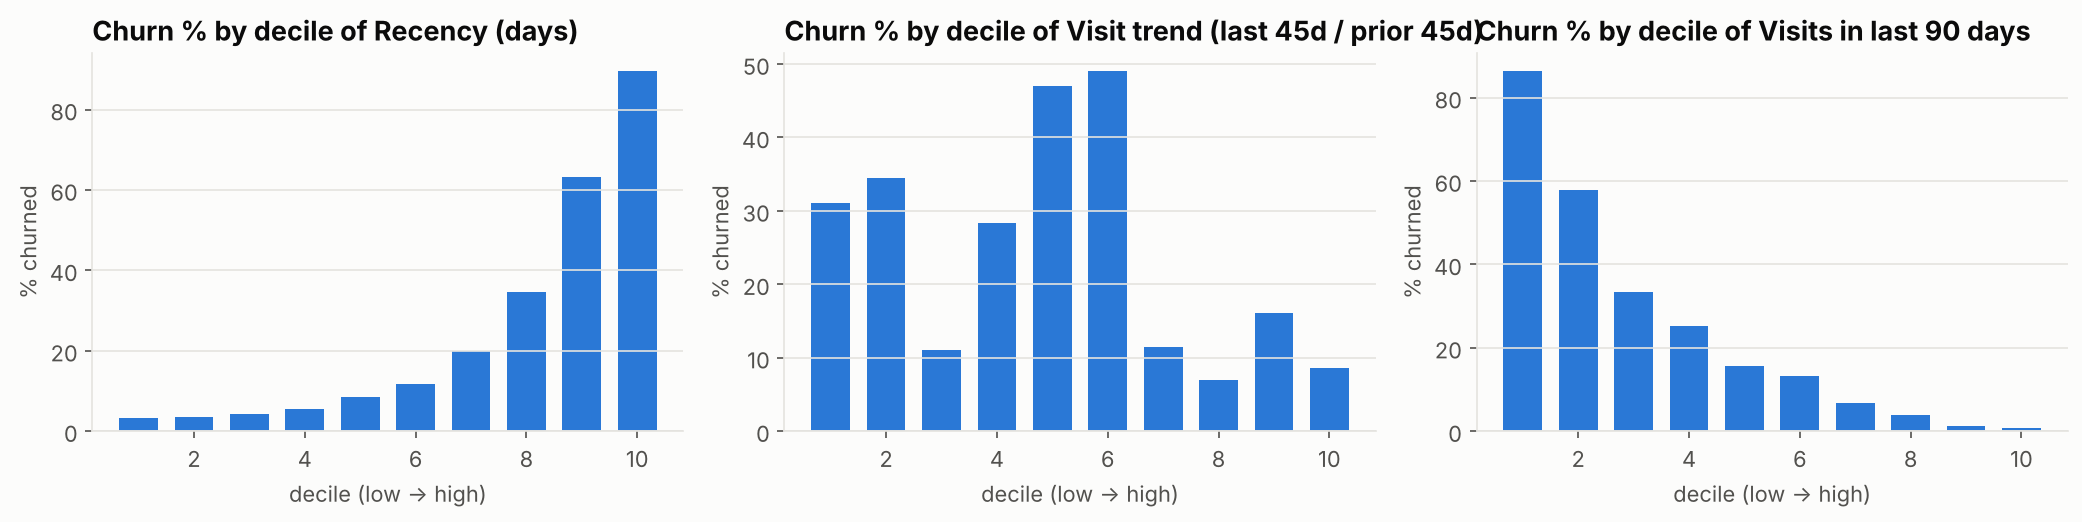

county,Kakamega,Nakuru,Machakos,Kajiado,Kiambu,Mombasa,Kisumu,Kilifi,Nyeri,Nairobi,Uasin Gishu
churn_%,29.7,28.6,27.0,26.1,25.4,25.1,24.7,23.4,22.4,21.8,21.8


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, col, title in [(ax[0], "recency_days", "Recency (days)"), (ax[1], "trend_45", "Visit trend (last 45d / prior 45d)"),
                      (ax[2], "freq_90", "Visits in last 90 days")]:
    q = pd.qcut(train[col].rank(method="first"), 10, labels=False)
    r = train.groupby(q).churned.mean() * 100
    a.bar(range(1, 11), r.values, color=PALETTE[0], width=0.7)
    a.set(title=f"Churn % by decile of {title}", xlabel="decile (low -> high)", ylabel="% churned")
    a.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "17_churn_signals.png")
train.groupby("county").churned.mean().sort_values(ascending=False).mul(100).round(1).to_frame("churn_%").T

## Models

In [4]:
NUM = ["recency_days", "freq_30", "freq_90", "freq_180", "freq_365", "spend_90", "spend_365", "avg_basket", "last_basket",
       "avg_cats_per_visit", "promo_share", "mpesa_share", "card_share", "weekend_share", "n_stores", "gap_mean", "gap_std",
       "trend_45", "recency_vs_gap", "n_categories_180", "age", "tenure_days"]
CAT = ["gender", "county", "store_format"]
for df in (train, test):
    df["age"] = df.age.fillna(train.age.median())
    df["n_categories_180"] = df.n_categories_180.fillna(0)
X, y, groups = train[NUM + CAT], train.churned, train.customer_id
Xt, yt = test[NUM + CAT], test.churned

pre_lr = ColumnTransformer([("num", StandardScaler(), NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
logit = make_pipeline(pre_lr, LogisticRegression(max_iter=2000, C=0.5))
pre_gb = ColumnTransformer([("num", "passthrough", NUM),
                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
gbm = make_pipeline(pre_gb, HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_leaf_nodes=24,
                                                           min_samples_leaf=50, l2_regularization=1.0, random_state=0))

def lift_at(y, p, frac=0.1):
    k = int(len(p) * frac)
    top = np.argsort(-p)[:k]
    return y.iloc[top].mean() / y.mean()

def evaluate(name, y, p):
    k = int(len(p) * 0.2)
    top = np.argsort(-p)[:k]
    return {"model": name, "ROC_AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, np.clip(p, 0, 1)) if p.max() <= 1 else np.nan,
            "lift_top10%": lift_at(y, p, 0.1), "recall_top20%": y.iloc[top].sum() / y.sum()}

cv = GroupKFold(n_splits=5)
cv_rows = []
base_cv = X.recency_days.to_numpy() / X.recency_days.max()
cv_rows.append(evaluate("Baseline: rank by recency", y, base_cv))
p_lr_cv = cross_val_predict(logit, X, y, cv=cv, groups=groups, method="predict_proba")[:, 1]
cv_rows.append(evaluate("Logistic regression", y, p_lr_cv))
p_gb_cv = cross_val_predict(gbm, X, y, cv=cv, groups=groups, method="predict_proba")[:, 1]
cv_rows.append(evaluate("Gradient boosting", y, p_gb_cv))
print("5-fold grouped cross-validation on the training snapshots:")
pd.DataFrame(cv_rows).set_index("model").round(3)

5-fold grouped cross-validation on the training snapshots:


,ROC_AUC,PR_AUC,Brier,lift_top10%,recall_top20%
model,,,,,
Baseline: rank by recency,0.880,0.762,0.109,3.675,0.625
Logistic regression,0.898,0.780,0.101,3.736,0.625
Gradient boosting,0.891,0.771,0.106,3.679,0.612


## Out-of-time test (snapshot 1 July 2026, outcome Jul-Sep 2026)

In [5]:
logit.fit(X, y); gbm.fit(X, y)
p_base = (Xt.recency_days / Xt.recency_days.max()).to_numpy()
p_lr = logit.predict_proba(Xt)[:, 1]
p_gb = gbm.predict_proba(Xt)[:, 1]
test_res = pd.DataFrame([evaluate("Baseline: rank by recency", yt, p_base),
                         evaluate("Logistic regression", yt, p_lr),
                         evaluate("Gradient boosting", yt, p_gb)]).set_index("model")
test_res.round(3).to_csv(TABLES / "churn_model_test_metrics.csv")
test_res.round(3)

,ROC_AUC,PR_AUC,Brier,lift_top10%,recall_top20%
model,,,,,
Baseline: rank by recency,0.891,0.787,0.109,3.602,0.632
Logistic regression,0.907,0.813,0.097,3.690,0.639
Gradient boosting,0.904,0.804,0.101,3.715,0.627


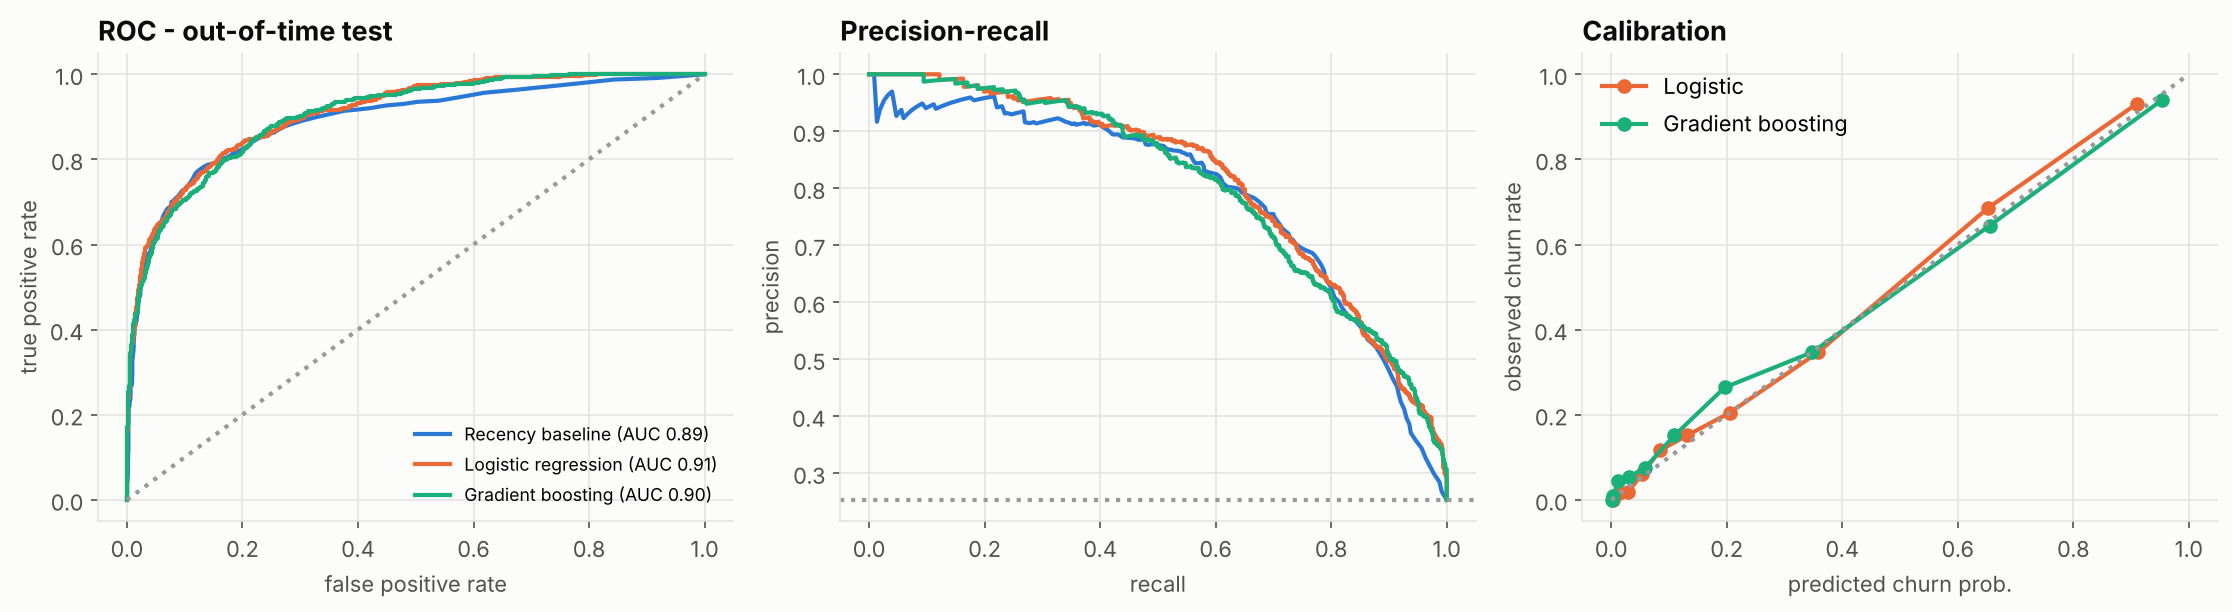

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for (name, p), col in zip([("Recency baseline", p_base), ("Logistic regression", p_lr), ("Gradient boosting", p_gb)], PALETTE):
    fpr, tpr, _ = roc_curve(yt, p)
    ax[0].plot(fpr, tpr, color=col, label=f"{name} (AUC {roc_auc_score(yt, p):.2f})")
    pr, rc, _ = precision_recall_curve(yt, p)
    ax[1].plot(rc, pr, color=col, label=name)
ax[0].plot([0, 1], [0, 1], color="#999", ls=":"); ax[0].set(title="ROC - out-of-time test", xlabel="false positive rate", ylabel="true positive rate")
ax[0].legend(loc="lower right", fontsize=8.5)
ax[1].axhline(yt.mean(), color="#999", ls=":"); ax[1].set(title="Precision-recall", xlabel="recall", ylabel="precision")
for p, nm, col in [(p_lr, "Logistic", PALETTE[1]), (p_gb, "Gradient boosting", PALETTE[2])]:
    fp, mp = calibration_curve(yt, p, n_bins=10, strategy="quantile")
    ax[2].plot(mp, fp, marker="o", color=col, label=nm)
ax[2].plot([0, 1], [0, 1], color="#999", ls=":"); ax[2].set(title="Calibration", xlabel="predicted churn prob.", ylabel="observed churn rate")
ax[2].legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "18_churn_model_eval.png")

## Lift chart - what CRM actually gets

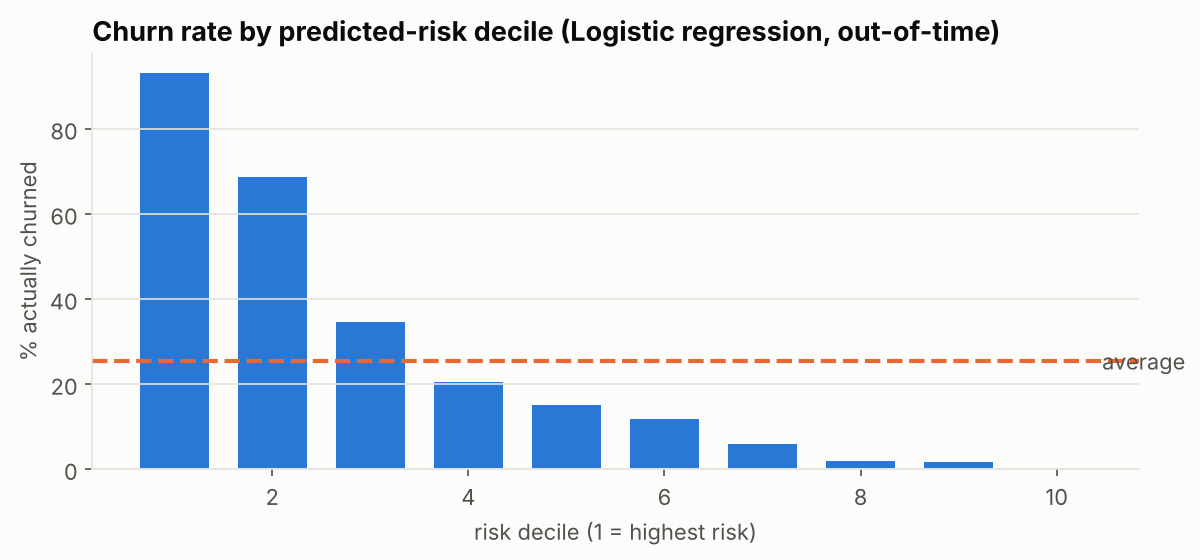

,customers,churn_rate,spend_90_at_stake,lift,cum_share_of_churners
decile,,,,,
1,318,0.931,5100.00,3.678,0.368
2,318,0.686,223555.00,2.709,0.639
3,317,0.347,645458.40,1.371,0.776
4,318,0.204,948798.85,0.808,0.857
5,318,0.151,1142069.05,0.596,0.917
6,317,0.117,1516052.10,0.461,0.963
7,318,0.060,2067036.75,0.236,0.986
8,317,0.019,2882572.40,0.075,0.994
9,318,0.016,4134581.45,0.062,1.000


In [7]:
best_name = test_res.ROC_AUC.idxmax()
p_best = {"Logistic regression": p_lr, "Gradient boosting": p_gb}.get(best_name, p_gb)
dec = pd.qcut(pd.Series(p_best).rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = pd.DataFrame({"decile": dec, "y": yt.to_numpy(),
                     "value": test.spend_90.to_numpy()}).groupby("decile", observed=True).agg(
    customers=("y", "size"), churn_rate=("y", "mean"), spend_90_at_stake=("value", "sum"))
lift["lift"] = lift.churn_rate / yt.mean()
lift["cum_share_of_churners"] = (lift.churn_rate * lift.customers).cumsum() / yt.sum()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(lift.index.astype(int), lift.churn_rate * 100, color=PALETTE[0], width=0.7)
ax.axhline(yt.mean() * 100, color=PALETTE[1], ls="--"); ax.text(10.4, yt.mean() * 100, " average", color=TEXT_2, va="center")
ax.set(title=f"Churn rate by predicted-risk decile ({best_name}, out-of-time)", xlabel="risk decile (1 = highest risk)",
       ylabel="% actually churned"); ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "19_churn_lift.png")
lift.round(3)

## Which features drive churn risk?

Logistic regression - largest standardised coefficients (+ = raises churn odds):


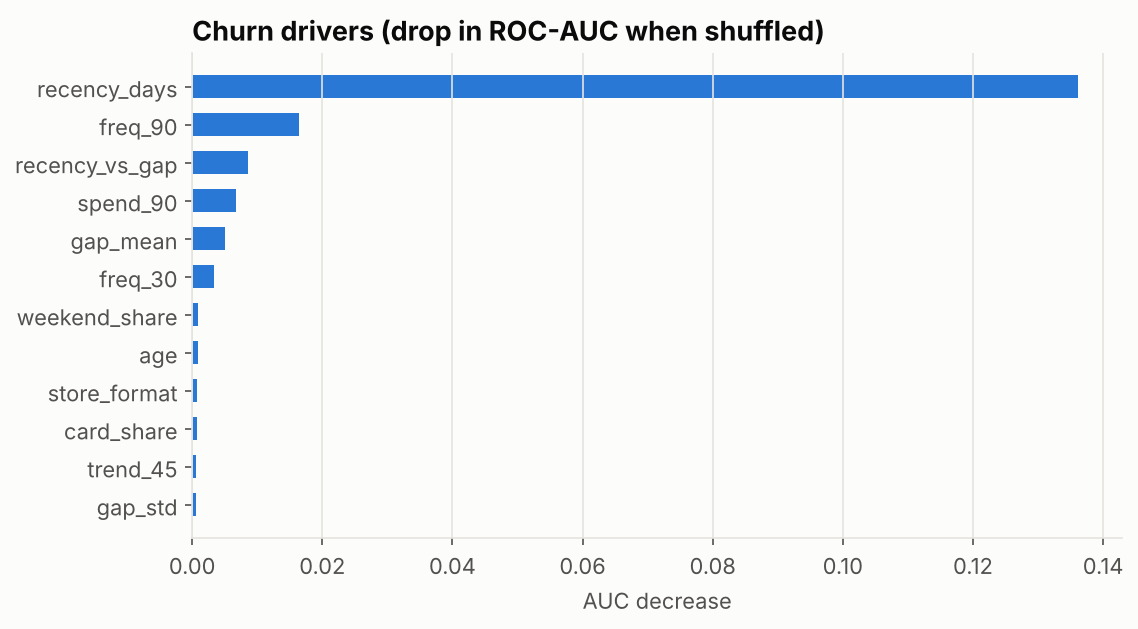

,coef
num__freq_90,-1.302
num__freq_30,-0.418
num__freq_180,-0.263
cat__county_Uasin Gishu,-0.224
cat__county_Nairobi,-0.214
cat__county_Machakos,-0.160
num__spend_365,0.108
cat__county_Nakuru,0.184
cat__county_Kakamega,0.243
num__recency_vs_gap,0.396


In [8]:
pi = permutation_importance(gbm, Xt, yt, n_repeats=5, random_state=0, scoring="roc_auc")
imp = pd.Series(pi.importances_mean, index=NUM + CAT).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(imp.index, imp.values, color=PALETTE[0], height=0.6)
ax.set(title="Churn drivers (drop in ROC-AUC when shuffled)", xlabel="AUC decrease"); ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "20_churn_drivers.png")

coefs = pd.Series(logit[-1].coef_[0], index=logit[0].get_feature_names_out()).sort_values()
print("Logistic regression - largest standardised coefficients (+ = raises churn odds):")
pd.concat([coefs.head(6), coefs.tail(6)]).round(3).to_frame("coef")

**Reading the drivers:** recent behaviour dominates. Few visits in the last 30-90 days, a long time since the last visit,
and a gap that is long *relative to the customer's own rhythm* (`recency_vs_gap`) all raise risk. Note the positive
coefficient on 12-month frequency: once recent frequency is held constant, a customer who *used to* visit often but has
slowed down is the classic drifting pattern. Home county Nakuru (and Kakamega) raise risk on top of behaviour - the
Nakuru competitor effect shows up independently. Demographics and payment method add almost nothing.

**Honest assessment:** a simple "rank by recency" rule is already a strong baseline (AUC ~0.89). The models add a modest
gain in AUC and PR-AUC, but their real value is **calibrated probabilities** (needed to put a shilling value on each
customer's risk) and the ability to include drivers like county and momentum that the rule ignores.

## Scoring today's customers (snapshot 30 Sep 2026) -> the CRM win-back list

In [9]:
now = build_snapshot("2026-09-30", label=False)
now["age"] = now.age.fillna(train.age.median()); now["n_categories_180"] = now.n_categories_180.fillna(0)
final = gbm.fit(pd.concat([X, Xt]), pd.concat([y, yt]))      # refit on all labelled data
now["churn_probability"] = final.predict_proba(now[NUM + CAT])[:, 1]
now["value_at_risk_12m"] = now.churn_probability * now.spend_365   # a lost member takes ~a year of spend with them
now["risk_band"] = pd.cut(now.churn_probability, [0, 0.2, 0.5, 1], labels=["Low", "Medium", "High"])
now = now.merge(customers[["customer_id", "home_store_id"]], on="customer_id")
cols = ["customer_id", "home_store_id", "county", "churn_probability", "risk_band", "recency_days", "freq_90",
        "spend_90", "spend_365", "value_at_risk_12m", "trend_45"]
now[cols].sort_values("value_at_risk_12m", ascending=False).round(3).to_csv(PROCESSED / "churn_scores_2026-09-30.csv", index=False)
print(now.risk_band.value_counts().to_string())
print(f"Expected 12-month spend at risk: KES {now.value_at_risk_12m.sum():,.0f}")
now[cols].sort_values("value_at_risk_12m", ascending=False).head(10).round(2)

risk_band
Low       1946
High       603
Medium     552
Expected 12-month spend at risk: KES 10,735,109


,customer_id,home_store_id,county,churn_probability,risk_band,recency_days,freq_90,spend_90,spend_365,value_at_risk_12m,trend_45
477,C00943,S015,Uasin Gishu,0.96,High,75,3,4087.0,92522.95,88648.69,0.25
612,C01228,S007,Mombasa,0.95,High,76,4,6611.0,82641.00,78323.34,0.20
294,C00566,S011,Nakuru,0.97,High,109,0,0.0,75452.50,73399.50,1.00
1631,C03197,S017,Kakamega,0.96,High,66,3,6059.0,70919.64,68011.62,0.25
928,C01841,S009,Kiambu,0.96,High,79,2,3804.0,67475.00,64776.88,0.33
785,C01575,S004,Nairobi,0.96,High,74,1,894.0,67060.85,64499.34,0.50
528,C01057,S003,Nairobi,0.95,High,63,5,5524.0,66689.50,63499.22,0.17
1266,C02478,S013,Kisumu,0.96,High,75,2,1886.0,65570.50,63094.61,0.33
2663,C05183,S004,Nairobi,0.89,High,48,3,1928.0,66002.25,58499.99,0.25
2994,C05792,S011,Nakuru,0.96,High,81,2,6438.0,60738.10,58488.18,0.33


## Business case for a win-back campaign
Assumptions (to be validated with a randomised holdout): an offer worth KES 150 or 300, 60% of contacted members redeem,
25% of would-be churners are saved, a saved member keeps ~12 months of their usual spend, gross margin 22%.
We contact only members whose **expected saved gross profit exceeds the expected cost of the offer**.

In [10]:
save_rate, margin, redeem = 0.25, 0.22, 0.60
now["exp_saved_gp"] = now.churn_probability * now.spend_365 * save_rate * margin
rows = []
for voucher in [150, 300]:
    cost_each = voucher * redeem
    tgt = now[now.exp_saved_gp > cost_each]
    gp, cost = tgt.exp_saved_gp.sum(), cost_each * len(tgt)
    rows.append({"offer_KES": voucher, "members_contacted": len(tgt), "expected_churners_in_list": tgt.churn_probability.sum(),
                 "expected_gp_saved_KES": gp, "campaign_cost_KES": cost, "net_KES": gp - cost, "ROI_%": 100 * (gp / cost - 1)})
    # compare with random targeting of the same number of members
    rnd = now.sample(len(tgt), random_state=0)
    rows[-1]["net_if_random_KES"] = rnd.exp_saved_gp.sum() - cost_each * len(tgt)
campaign = pd.DataFrame(rows).round(0)
campaign.to_csv(TABLES / "churn_campaign_business_case.csv", index=False)
campaign

,offer_KES,members_contacted,expected_churners_in_list,expected_gp_saved_KES,campaign_cost_KES,net_KES,ROI_%,net_if_random_KES
0,150,1271,579.0,512203.0,114390.0,397813.0,348.0,135386.0
1,300,709,433.0,440786.0,127620.0,313166.0,245.0,11093.0


On these assumptions a model-targeted KES 150 offer to ~1,270 members nets about KES 0.4M of gross profit - roughly three
times what the same offer sent to the same number of *randomly* chosen members would return (and at KES 300 random
targeting barely breaks even). That gap is the value of the model. The assumptions (save rate especially) must be
measured with a holdout group in the first campaign.

## Model card (summary)
* **Population:** active loyalty members (purchase in last 180 days, tenure >= 30 days). Walk-ins cannot be scored.
* **Label:** no purchase in the next 90 days.
* **Validation:** grouped 5-fold CV on three stacked training snapshots + a single out-of-time test snapshot (Jul 2026).
* **Result vs success criteria:** see the out-of-time table - ROC-AUC and top-decile lift are compared to the >= 0.75 and
  >= 2.5x targets set in Milestone 1.
* **Fairness check:** gender and age have negligible importance; the model does not target by demographics.
* **Limitations:** a "churned" member may still shop without scanning their card; 90-day horizon misses slow drift;
  retrain quarterly; validate the campaign with a randomised holdout before scaling.